(mmm_likelihood_reweighting)=
# Reweighting Likelihoods Instead of Refitting

Companion to {ref}`mmm_prior_reweighting`. Same idea, applied to the **likelihood**: how much a lift test counts, whether to drop one, whether the noise should have heavy tails. Fit the lift-calibrated model **once**, reweight the draws, and let Pareto k̂ and the ESS say when to refit.

The model and data are those of {ref}`mmm_prior_sensitivity`: two channels, a business prior on ROAS and two lift tests on x1.

The notebook runs in about 3 minutes on 6 CPU cores, nearly all of it in the fits (about 20 seconds each):

1. Fit the model once (the reference fit).
2. Stronger and weaker lift tests, each checked against a full refit.
3. Heavy-tailed sales noise (StudentT).
4. A sweep with no refits, including combined prior and likelihood changes.

**How it works.** The weight of a draw is `new likelihood / reference likelihood`, evaluated at that draw's parameters. For the lift tests that is two terms. For the sales noise it is one term per week, 131 of them, so the weights spread out faster than for a prior change: **likelihood changes are less forgiving**, and the sweep below shows where it stops working. The ingredients are saved by the fit: `mu`, `y_sigma` and the model's estimate of each lift test.

| Pareto k̂ | verdict |
|---|---|
| < 0.5 | use the reweighted posterior |
| 0.5 – 0.7 | check it with a refit if it matters |
| ≥ 0.7 | refit |

## Prepare Notebook

In [1]:
%config InlineBackend.figure_format = "retina"

import logging
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from arviz_stats.base import array_stats
from IPython.display import display
from pymc_extras.prior import Prior
from scipy import stats

from pymc_marketing.hsgp_kwargs import HSGPKwargs
from pymc_marketing.mmm import MMM, GeometricAdstock, LogisticSaturation
from pymc_marketing.paths import data_dir

warnings.filterwarnings("ignore")
logging.getLogger("pymc").setLevel(
    logging.WARNING
)  # keep sampler warnings, drop the start-up message
az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [12, 7]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

## Data and Reference Fit

In [2]:
raw_df = pd.read_csv(data_dir / "mmm_roas_data.csv", parse_dates=["date"])
X = raw_df[["date", "x1", "x2"]]
y = raw_df["y"]
channel_columns = ["x1", "x2"]

The model is the one of the sensitivity notebook, with the business prior (ROAS 100 ± 20 for `x1` and 150 ± 50 for `x2`) and two lift tests on `x1`.

In [3]:
# The model of the sensitivity notebook: weakly informative media priors, HSGP baseline, yearly seasonality.
baseline_model_config = {
    "likelihood": Prior("Normal", sigma=Prior("HalfNormal", sigma=0.5)),
    "gamma_fourier": Prior("Normal", mu=0, sigma=2, dims="fourier_mode"),
    "intercept_tvp_config": HSGPKwargs(
        m=50, L=None, eta_lam=1.0, ls_mu=5.0, ls_sigma=10.0, cov_func=None
    ),
    "adstock_alpha": Prior("Beta", alpha=2, beta=3, dims="channel"),
    "saturation_lam": Prior("Gamma", alpha=2, beta=2, dims="channel"),
    "saturation_beta": Prior("HalfNormal", sigma=1, dims="channel"),
}
# Business prior: ROAS target and sigma per channel.
reference_business = {"roas": [100.0, 150.0], "sigma": [20.0, 50.0]}

sampler_config = {
    "tune": 1_000,
    "chains": 6,
    "cores": 6,
    "draws": 2_000,
    "progressbar": False,
    "nuts": {"adaptation": "draw_diag", "target_accept": 0.94},
}

`fit` builds, fits and post-processes the model, and `spec` lists what differs from the reference. `log_ratio` turns a `spec` into one log weight per draw.

In [4]:
lift_tests = (
    pd.DataFrame(  # the two synthetic lift tests of the sensitivity notebook, on x1
        {
            "channel": ["x1", "x1"],
            "x": [0.25, 0.8],
            "delta_x": [0.25, 0.8],
            "delta_y": [23.34703279570842, 74.71050494626694],
            "sigma": [3.0, 3.0],
            "date": pd.to_datetime(
                [
                    X["date"].max() - pd.Timedelta(weeks=50),
                    X["date"].max() - pd.Timedelta(weeks=14),
                ]
            ),
        }
    )
)
reference_lift_sigma = 3.0


def fit(seed, spec=None):
    """Fit the lift-calibrated model; `spec` lists what differs from the reference (see log_ratio)."""
    spec = spec or {}
    config = dict(baseline_model_config)
    if "sat_beta" in spec:
        config["saturation_beta"] = Prior(
            "HalfNormal", sigma=spec["sat_beta"], dims="channel"
        )
    if "sales_t_nu" in spec:
        config["likelihood"] = Prior(
            "StudentT", nu=spec["sales_t_nu"], sigma=Prior("HalfNormal", sigma=0.5)
        )
    mmm = MMM(
        adstock=GeometricAdstock(l_max=4),
        saturation=LogisticSaturation(),
        date_column="date",
        channel_columns=channel_columns,
        target_column="y",
        time_varying_intercept=True,
        time_varying_media=False,
        yearly_seasonality=5,
        model_config=config,
    )
    mmm.build_model(X, y)
    lift = lift_tests.iloc[spec.get("lift_keep", [0, 1])].assign(
        sigma=spec.get("lift_sigma", reference_lift_sigma)
    )
    if len(lift):
        mmm.add_lift_test_measurements(
            df_lift_test=lift.reset_index(drop=True),
            likelihood=Prior("StudentT", nu=spec["lift_t_nu"])
            if "lift_t_nu" in spec
            else None,
        )
    mmm.add_original_scale_contribution_variable(
        var=["channel_contribution", "fourier_contribution", "intercept_contribution"]
    )
    mmm.add_cost_per_target_calibration(
        data=X,
        calibration_data=pd.DataFrame(
            {"channel": channel_columns, **spec.get("business", reference_business)}
        ),
        name_prefix="business_prior",
        target_column="roas",
        target_per_cost=True,
    )
    mmm.fit(X, y, random_seed=np.random.default_rng(seed), **sampler_config)
    mmm.idata["posterior"]["ROAS"] = (
        mmm.incrementality.compute_incremental_contribution("all_time")
        / mmm.idata["constant_data"]["channel_data"].sum("date")
    )
    return mmm


def lift_logpdf(obs, est, sigma, nu=None):
    """Return the log density of the lift measurements: Normal, or StudentT when `nu` is given."""
    return (
        stats.norm.logpdf(obs, est, sigma)
        if nu is None
        else stats.t.logpdf(obs, nu, est, sigma)
    )


def log_ratio(spec, mmm):
    """Return log(new / reference) per draw, from the saved draws of the reference fit `mmm`.

    The spec keys are `lift_sigma` (standard error of the lift tests), `lift_keep` (rows of `lift_tests` kept),
    `lift_t_nu` (StudentT instead of Normal lift noise), `sales_t_nu` (StudentT instead of Normal sales noise),
    `business` (new ROAS target and sigma) and `sat_beta` (HalfNormal scale of `saturation_beta`). Only a fixed
    `nu` works: a prior on `nu` adds a sampled variable and needs a refit. Terms that do not change cancel and
    are left out.
    """
    total = 0.0
    observed = mmm.idata["observed_data"]
    if any(k in spec for k in ("lift_sigma", "lift_keep", "lift_t_nu")):
        scale = float(
            mmm.idata["constant_data"]["target_scale"]
        )  # the model works on the scaled target
        obs = observed["lift_measurements"].values
        est = draws(mmm, "lift_measurements_model_estimated_lift")
        keep = list(spec.get("lift_keep", [0, 1]))
        sigma = spec.get("lift_sigma", reference_lift_sigma) / scale
        new = lift_logpdf(obs[keep], est[:, keep], sigma, spec.get("lift_t_nu"))
        total = (
            total
            + new.sum(1)
            - lift_logpdf(obs, est, reference_lift_sigma / scale).sum(1)
        )
    if "sales_t_nu" in spec:
        mu, sigma, sales = (
            draws(mmm, "mu"),
            draws(mmm, "y_sigma")[:, None],
            observed["y"].values,
        )
        new = stats.t.logpdf(sales, spec["sales_t_nu"], mu, sigma)
        total = total + (new - stats.norm.logpdf(sales, mu, sigma)).sum(1)
    if "business" in spec:
        roas = draws(mmm, "ROAS")
        new = stats.norm.logpdf(
            spec["business"]["roas"], roas, spec["business"]["sigma"]
        )
        old = stats.norm.logpdf(
            reference_business["roas"], roas, reference_business["sigma"]
        )
        total = total + (new - old).sum(1)
    if "sat_beta" in spec:
        x = draws(mmm, "saturation_beta")
        total = total + (
            stats.halfnorm(scale=spec["sat_beta"]).logpdf(x)
            - stats.halfnorm(scale=1.0).logpdf(x)
        ).sum(1)
    return total

In [5]:
def psis(log_ratio, r_eff=1.0):
    """Pareto-smoothed importance weights of a log importance ratio (one value per draw), with diagnostics."""
    # ArviZ 1.x smooths the weights exp(-x) of its input x, so the log ratio goes in negated.
    log_w, k_hat = array_stats.psislw(-np.asarray(log_ratio, dtype=float), r_eff=r_eff)
    w = np.exp(log_w - log_w.max())
    w /= w.sum()
    k_hat = float(k_hat)
    verdicts = ("use it", "check", "refit")
    return {
        "w": w,
        "k_hat": k_hat,
        "ess_pct": 100 / np.sum(w**2) / len(w),
        "verdict": verdicts[np.searchsorted([0.5, 0.7], k_hat, side="right")],
    }


def draws(mmm, name):
    """Posterior draws of `name` with chains and draws merged, shape (n_draws, ...)."""
    return (
        mmm.idata["posterior"][name]
        .stack(s=("chain", "draw"))
        .transpose("s", ...)
        .values
    )


def relative_efficiency(
    mmm, names=("ROAS", "adstock_alpha", "saturation_lam", "saturation_beta", "y_sigma")
):
    """Mean ESS of the reported quantities over the number of draws, capped at 1 (as in az.loo)."""
    posterior = mmm.idata["posterior"]
    ess = az.ess(posterior.to_dataset()[list(names)], method="mean")
    n_draws = posterior.sizes["chain"] * posterior.sizes["draw"]
    return min(
        float(
            np.mean(np.concatenate([ess[v].values.ravel() for v in names])) / n_draws
        ),
        1.0,
    )

In [6]:
def plot_roas(roas, w, refit=None, title=""):
    """Plot ROAS per channel: reference posterior, reweighted posterior and (optionally) the full refit."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
    for j, ax in enumerate(axes):
        lo, hi = np.quantile(roas[:, j], [0.001, 0.999])
        if refit is not None:
            lo, hi = (
                min(lo, refit[:, j].min()),
                max(hi, np.quantile(refit[:, j], 0.999)),
            )
        bins = np.linspace(lo, hi, 50)
        ax.hist(
            roas[:, j],
            bins,
            density=True,
            histtype="step",
            color="0.55",
            lw=1.5,
            label="reference fit",
        )
        ax.hist(
            roas[:, j],
            bins,
            weights=w,
            density=True,
            histtype="step",
            color="C0",
            lw=2,
            label="reweighted",
        )
        if refit is not None:
            ax.hist(
                refit[:, j],
                bins,
                density=True,
                histtype="step",
                color="k",
                lw=1.5,
                ls="--",
                label="full refit",
            )
        ax.set(title=f"ROAS {channel_columns[j]}", yticks=[])
    axes[0].legend(frameon=False)
    fig.suptitle(title, fontweight="bold")
    return fig


def compare(roas, w, refit=None):
    """Posterior mean and SD of ROAS: reference, reweighted, refit; error in refit SDs."""
    rows = []
    for j, channel in enumerate(channel_columns):
        mean = np.sum(w * roas[:, j])
        row = {
            "channel": channel,
            "reference": roas[:, j].mean(),
            "reweighted": mean,
            "reweighted sd": np.sqrt(np.sum(w * (roas[:, j] - mean) ** 2)),
        }
        if refit is not None:
            row |= {
                "refit": refit[:, j].mean(),
                "refit sd": refit[:, j].std(),
                "|reweighted - refit| / refit sd": abs(mean - refit[:, j].mean())
                / refit[:, j].std(),
            }
        rows.append(row)
    return pd.DataFrame(rows).set_index("channel").round(2)

In [7]:
ref = fit(seed=1)

Output()

In [8]:
roas = draws(ref, "ROAS")
r_eff = relative_efficiency(ref)
print(f"relative MCMC efficiency {r_eff:.2f}")
print(f"ROAS mean {roas.mean(0).round(1)}, sd {roas.std(0).round(1)}")

relative MCMC efficiency 0.85
ROAS mean [110.5 142.3], sd [ 6.4 13.9]


The lift tests pull x1 ROAS down to about 110 (the observational fit alone gave 170).

## Stronger and Weaker Lift Tests

The refit (dashed) is only here to check the answer. Refits with different seeds differ a little too, so compare `|reweighted - refit|` with that noise (about 0.01 SD in the evidence below), not with zero.

In [9]:
def try_spec(label, spec, seed, refit=True):
    """Reweight the reference draws to `spec`; optionally refit to check the answer."""
    start = time.perf_counter()
    result = psis(log_ratio(spec, ref), r_eff)
    print(label)
    print(
        f"reweighting took {time.perf_counter() - start:.3f} s: k-hat = {result['k_hat']:.2f}, "
        f"ESS = {result['ess_pct']:.0f}% of the draws -> {result['verdict'].upper()}"
    )
    refit_roas = None
    if refit:
        start = time.perf_counter()
        result["refit"] = fit(seed, spec)
        refit_roas = draws(result["refit"], "ROAS")
        print(f"full refit took {time.perf_counter() - start:.0f} s")
    plot_roas(roas, result["w"], refit_roas, title=label)
    plt.show()
    display(compare(roas, result["w"], refit_roas))
    return result

Lift tests count more: standard error 2 instead of 3
reweighting took 0.004 s: k-hat = -0.49, ESS = 22% of the draws -> USE IT


Output()

full refit took 16 s


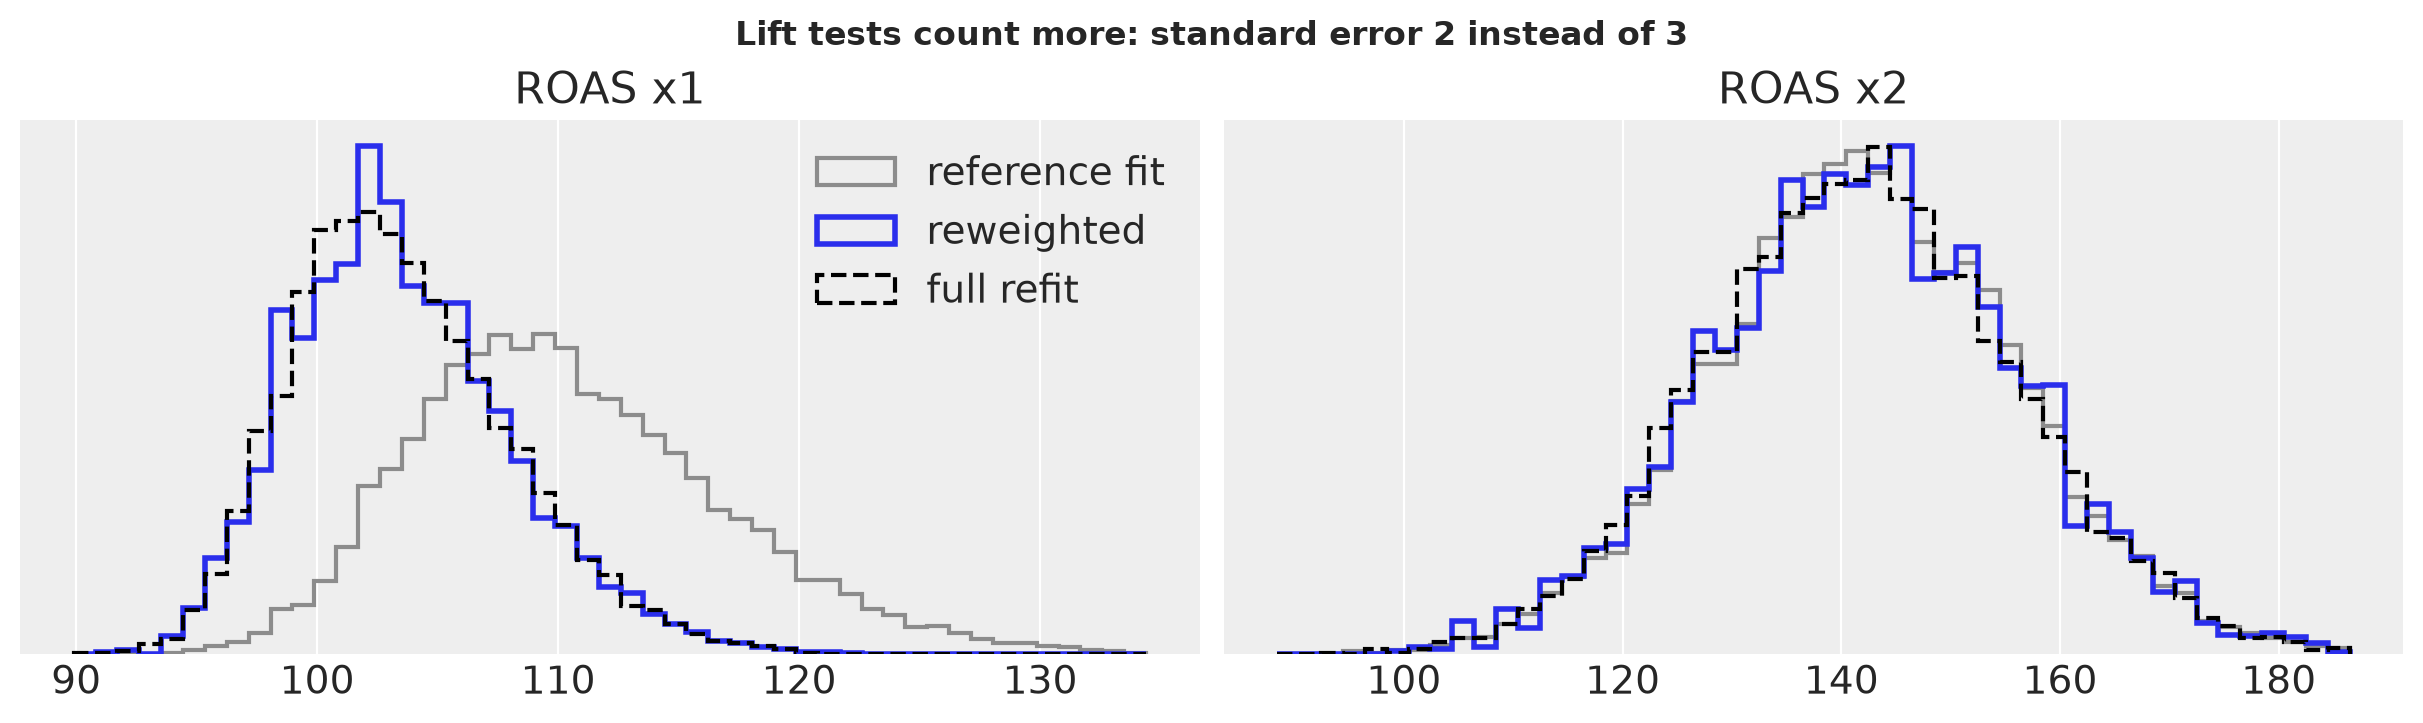

,reference,reweighted,reweighted sd,refit,refit sd,|reweighted - refit| / refit sd
channel,,,,,,
x1,110.46,103.55,4.52,103.53,4.54,0.00
x2,142.28,142.12,14.07,141.81,13.99,0.02


In [10]:
r_strong = try_spec(
    "Lift tests count more: standard error 2 instead of 3", {"lift_sigma": 2.0}, seed=2
)

Tightening a test is a mild change for the weights (k̂ below 0.5): the reweighted posterior matches the refit. Loosening it means asking for draws the tighter fit rarely visited.

Lift tests count less: standard error 4 instead of 3
reweighting took 0.004 s: k-hat = 0.62, ESS = 4% of the draws -> CHECK


Output()

full refit took 17 s


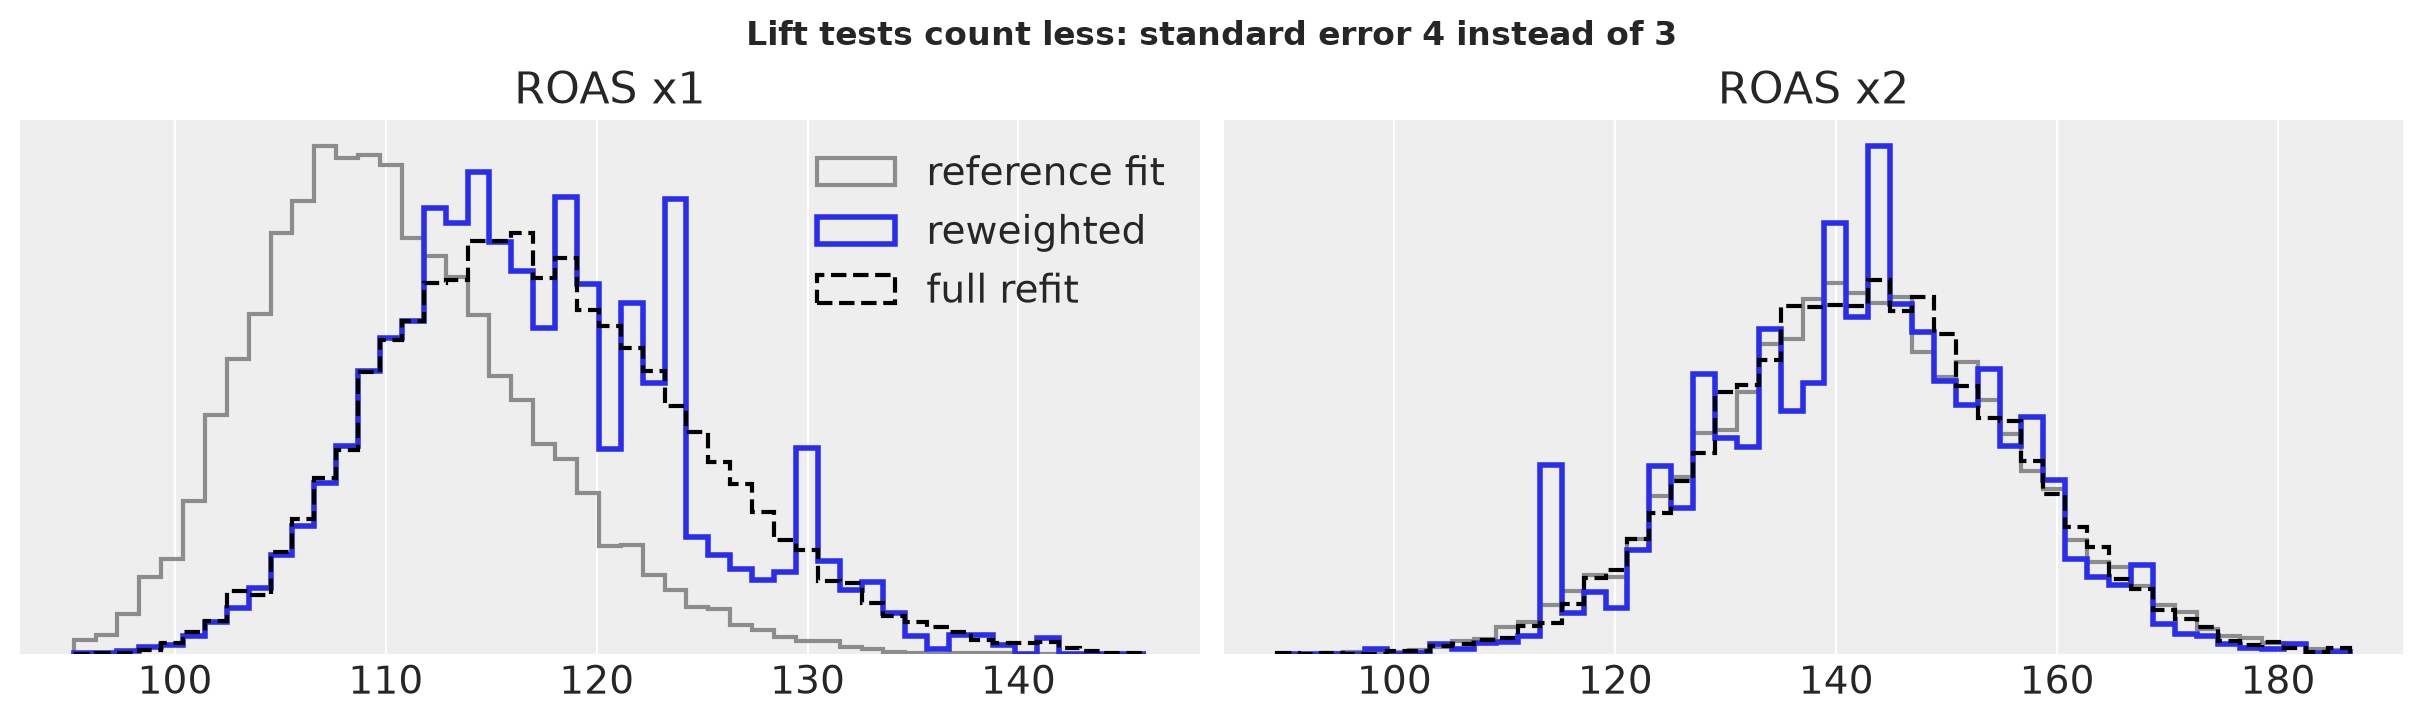

,reference,reweighted,reweighted sd,refit,refit sd,|reweighted - refit| / refit sd
channel,,,,,,
x1,110.46,117.14,7.29,117.46,7.57,0.04
x2,142.28,141.93,13.48,142.48,13.43,0.04


In [11]:
r_weak = try_spec(
    "Lift tests count less: standard error 4 instead of 3", {"lift_sigma": 4.0}, seed=3
)

k̂ is above 0.5 and the ESS is a few percent of the draws: **check**. The direction and size of the shift are right; the shape of the posterior is where it can be off.

## Heavy-Tailed Sales Noise

Does the ROAS estimate depend on the noise being Normal? A StudentT likelihood with a fixed number of degrees of freedom `nu` keeps the same sampled variables, so it can be reweighted. (A *prior* on `nu` adds a variable and needs a refit.)

Sales noise StudentT, nu = 30
reweighting took 0.100 s: k-hat = 0.24, ESS = 50% of the draws -> USE IT


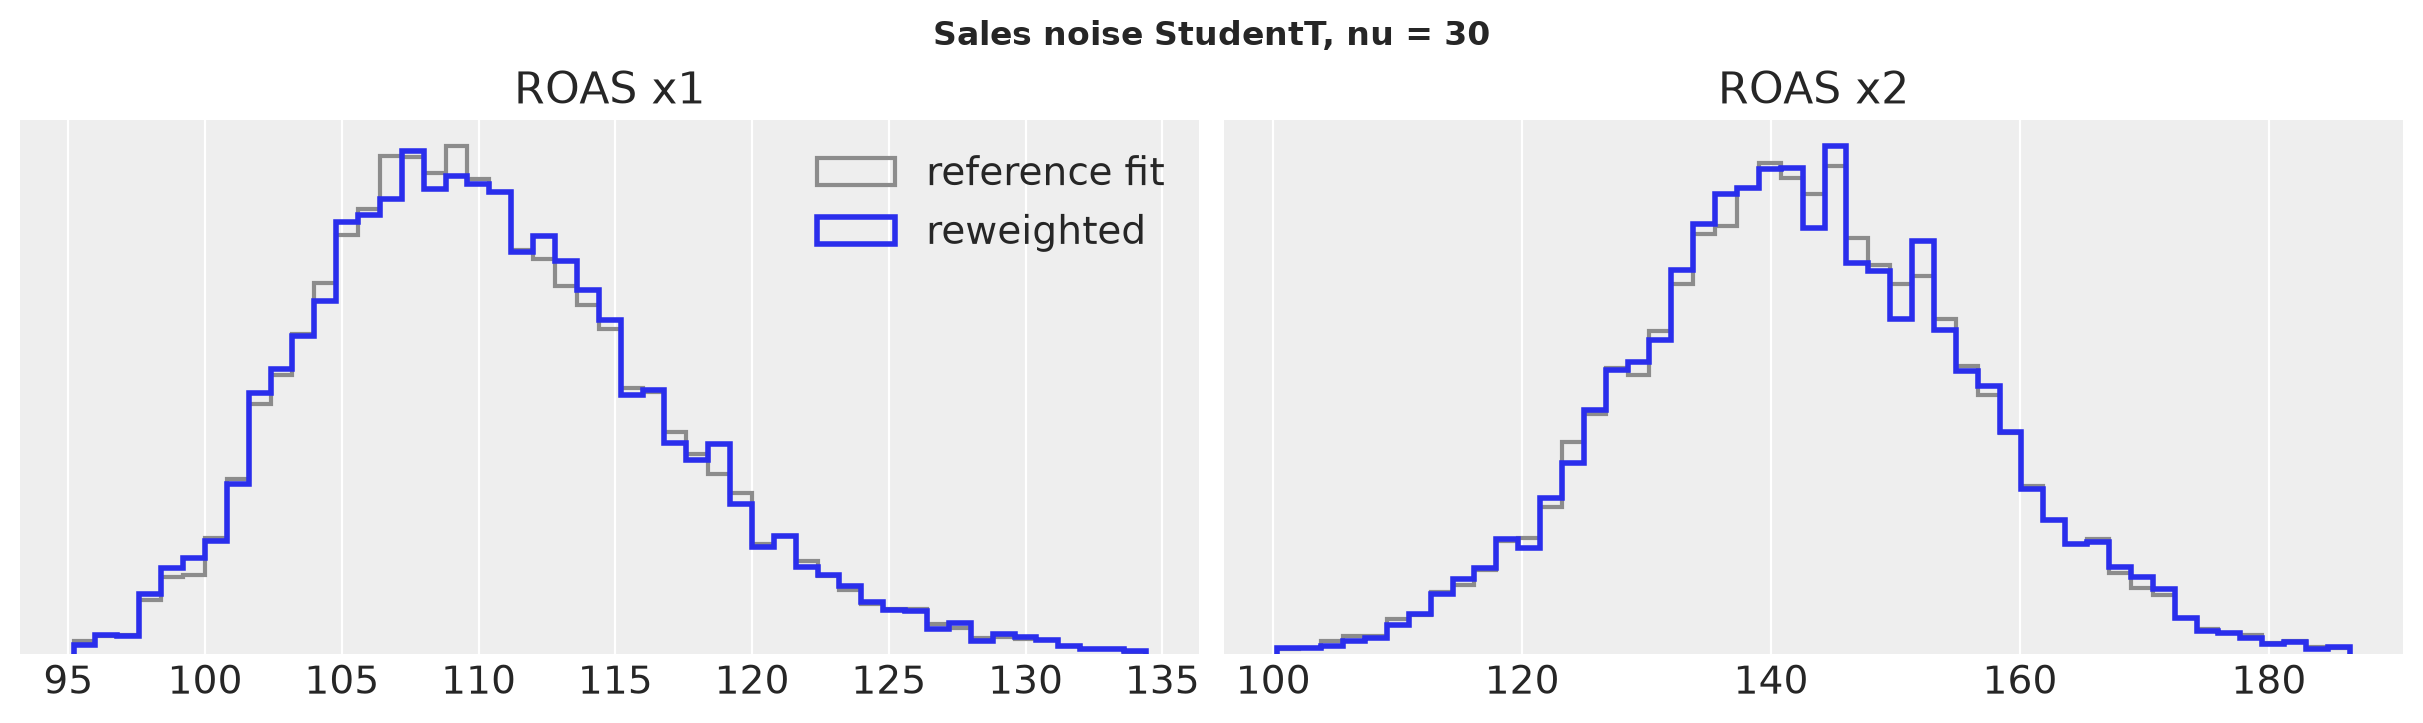

,reference,reweighted,reweighted sd
channel,,,
x1,110.46,110.47,6.46
x2,142.28,142.32,13.85


Sales noise StudentT, nu = 10
reweighting took 0.091 s: k-hat = 0.61, ESS = 3% of the draws -> CHECK


Output()

full refit took 17 s


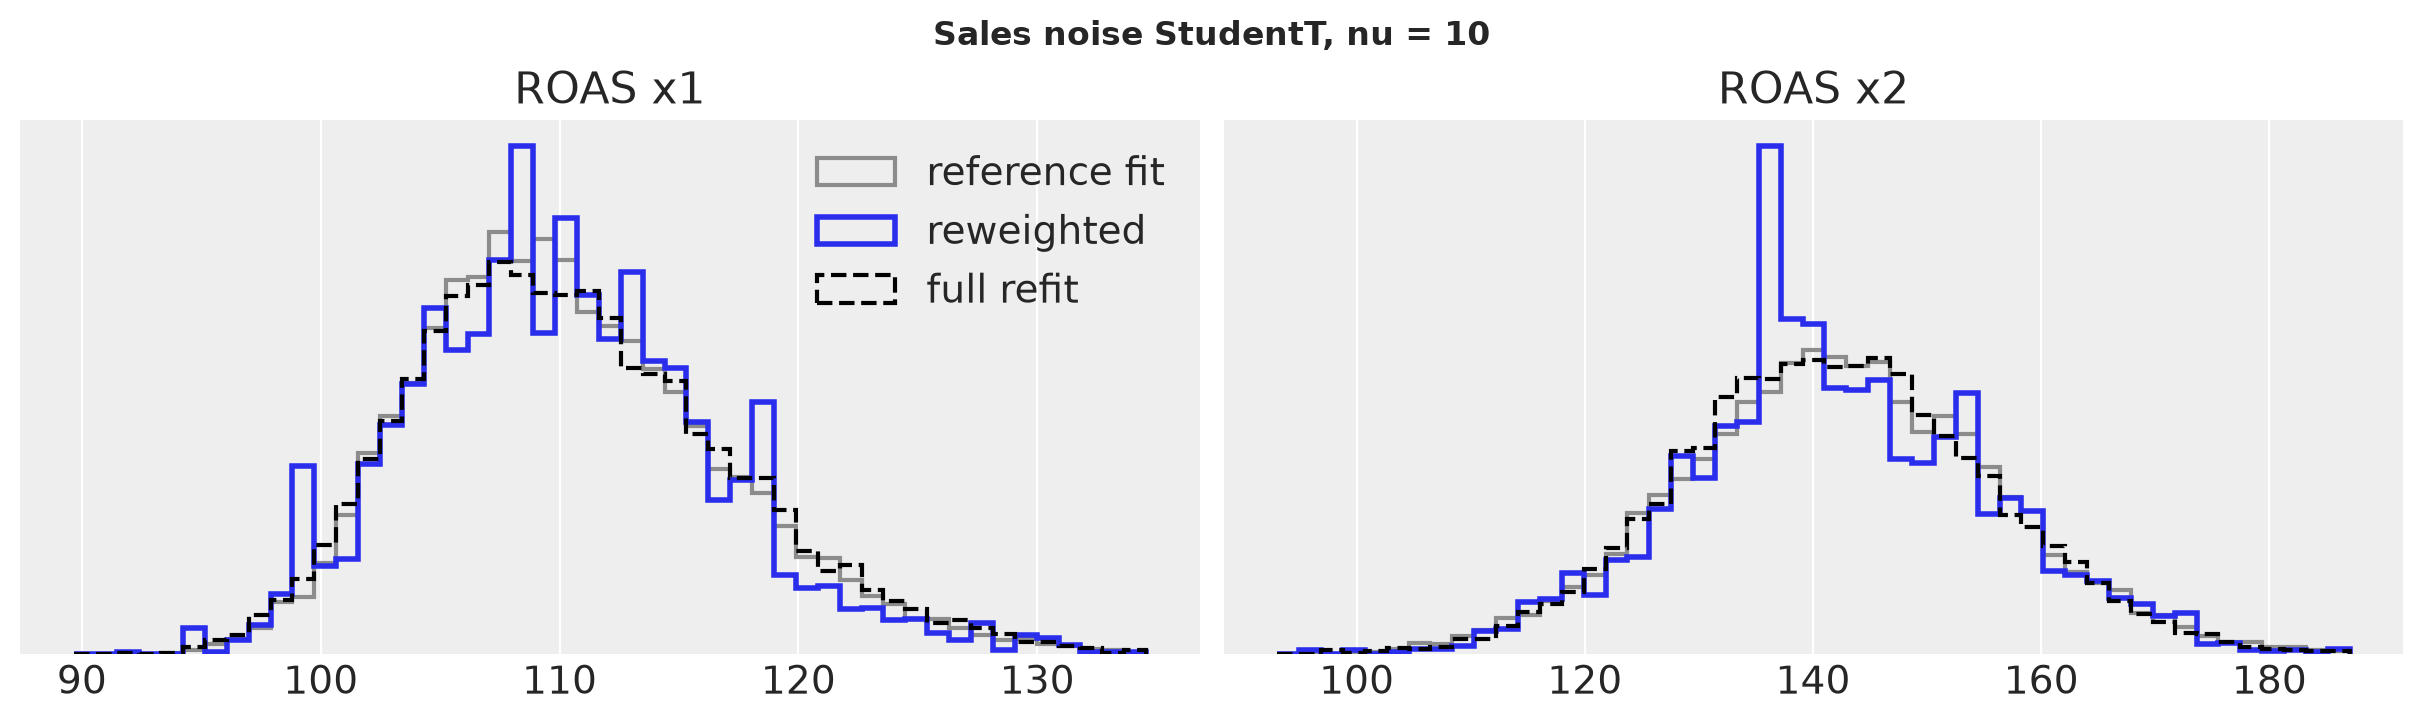

,reference,reweighted,reweighted sd,refit,refit sd,|reweighted - refit| / refit sd
channel,,,,,,
x1,110.46,110.18,6.35,110.53,6.66,0.05
x2,142.28,141.98,13.42,141.97,13.47,0.00


In [12]:
r_t30 = try_spec(
    "Sales noise StudentT, nu = 30", {"sales_t_nu": 30.0}, seed=4, refit=False
)
r_t10 = try_spec("Sales noise StudentT, nu = 10", {"sales_t_nu": 10.0}, seed=5)

With `nu = 30` the answer is "no change" (k̂ below 0.5): the data have no outliers that heavier tails would change. With `nu = 10` k̂ is in the check band and the weights rest on a few percent of the draws; here the reweighted means agree with the refit. The same change had k̂ 0.98 in the reference fit behind the evidence below, so a value in this band means "refit if it matters".

## A Sensitivity Sweep With No Refits

**refit** rows are changes the reference draws cannot answer; run a real fit for them. Their means are left out on purpose.

In [13]:
def sweep(candidates):
    """Reweight the reference draws to each candidate; one row per candidate, no refits."""
    rows = [
        {
            "change": "reference fit",
            "k-hat": np.nan,
            "ESS %": 100.0,
            "verdict": "-",
            **{f"ROAS {c}": roas[:, j].mean() for j, c in enumerate(channel_columns)},
        }
    ]
    for label, spec in candidates.items():
        result = psis(log_ratio(spec, ref), r_eff)
        means = result["w"] @ roas if result["verdict"] != "refit" else [np.nan, np.nan]
        rows.append(
            {
                "change": label,
                "k-hat": result["k_hat"],
                "ESS %": result["ess_pct"],
                "verdict": result["verdict"],
                **{f"ROAS {c}": means[j] for j, c in enumerate(channel_columns)},
            }
        )
    return pd.DataFrame(rows).set_index("change").round(2)

In [14]:
candidates = {
    "lift sigma 1.5": {"lift_sigma": 1.5},
    "lift sigma 2": {"lift_sigma": 2.0},
    "lift sigma 4": {"lift_sigma": 4.0},
    "lift sigma 6": {"lift_sigma": 6.0},
    "drop lift test 1": {"lift_keep": [1]},
    "drop lift test 2": {"lift_keep": [0]},
    "lift noise StudentT nu=30": {"lift_t_nu": 30.0},
    "lift noise StudentT nu=10": {"lift_t_nu": 10.0},
    "sales noise StudentT nu=30": {"sales_t_nu": 30.0},
    "sales noise StudentT nu=10": {"sales_t_nu": 10.0},
    "sales noise StudentT nu=3": {"sales_t_nu": 3.0},
    "business prior x1 target 120": {
        "business": {"roas": [120.0, 150.0], "sigma": [20.0, 50.0]}
    },
    "business prior sigma 2x wider": {
        "business": {"roas": [100.0, 150.0], "sigma": [40.0, 100.0]}
    },
    "lift sigma 2 + sales StudentT nu=30": {"lift_sigma": 2.0, "sales_t_nu": 30.0},
    "lift sigma 4 + sales StudentT nu=10": {"lift_sigma": 4.0, "sales_t_nu": 10.0},
}
sweep(candidates)

,k-hat,ESS %,verdict,ROAS x1,ROAS x2
change,,,,,
reference fit,NaN,100.00,-,110.46,142.28
lift sigma 1.5,-0.25,6.44,use it,100.52,142.15
lift sigma 2,-0.49,21.92,use it,103.55,142.12
lift sigma 4,0.62,3.78,check,117.14,141.93
lift sigma 6,1.08,0.08,refit,NaN,NaN
drop lift test 1,0.87,0.45,refit,NaN,NaN
drop lift test 2,1.42,0.03,refit,NaN,NaN
lift noise StudentT nu=30,0.61,31.45,check,112.39,142.21
lift noise StudentT nu=10,0.92,0.50,refit,NaN,NaN


Changes to the business prior are cheap (two terms, on a quantity the data constrain well). Making the lift tests count more is safe; making them count less is **check** at a factor 1.3 and **refit** beyond. Removing a lift test is a refit. StudentT sales noise is fine at `nu = 30`, **check** at 10 and **refit** at 3. Two borderline changes together (lift sigma 4 with `nu = 10`) end in **refit**: the log ratios add.

## Limits

- **Only the likelihood terms change, not the parameters.** Same sampled variables. A prior on `nu`, a different adstock or saturation function, new controls or more data need a refit. Dropping weeks is the same computation (leave-out), but the evidence here does not cover it.
- **k̂ is itself estimated from the draws.** For the same change it differed by up to about 0.4 between this notebook's reference fit and the one behind the evidence below (the StudentT sales rows most). Treat 0.5 and 0.7 as zones, not sharp lines.
- **Likelihood changes need more care than prior changes.** At k̂ ≥ 1 the reweighted mean was no better than the reference for the quantities the change moves (median error 1.03 against 0.89 refit SDs, closer in 57% of cases), and it disturbed quantities that should not move. Treat k̂ ≥ 0.7 as "refit" and k̂ in 0.5 – 0.7 as "check".

## Evidence

43 likelihood and combined changes (lift sigma, dropped lift tests, StudentT lift and sales noise, the business prior, and combinations with prior changes), each reweighted from one reference fit and compared with a full refit. Errors are in refit posterior SDs; two refits of one scenario differ by 0.007. "Do nothing" is the unweighted reference posterior. Scenarios were selected to cover the k̂ range evenly, so the counts say nothing about how often a typical change is safe; the bins are small (8 to 10 scenarios), so read the table as a pattern, not as precise rates. Scripts, tables and figures are in the [evidence folder](https://github.com/hansamos/prior_sensitivity_pymc_marketing/tree/main/evidence).

| Pareto k̂ | scenarios | ESS (median) | error, worst quantity (median) | error, do nothing | closer than the reference |
|---|---|---|---|---|---|
| <0.3 | 8 | 96% | 0.017 | 0.11 | 100% of moved quantities |
| 0.3-0.5 | 8 | 55% | 0.026 | 0.41 | 100% of moved quantities |
| 0.5-0.7 | 8 | 12% | 0.057 | 0.7 | 100% of moved quantities |
| 0.7-1 | 9 | 1% | 0.32 | 1.4 | 82% of moved quantities |
| >=1 | 10 | 0% | 3.4 | 5.1 | 57% of moved quantities |

## References

- Vehtari, A., Simpson, D., Gelman, A., Yao, Y., Gabry, J. (2024). Pareto smoothed importance sampling. *Journal of Machine Learning Research*, 25(72), 1-58. [jmlr.org/papers/v25/19-556](https://jmlr.org/papers/v25/19-556.html)
- Kallioinen, N., Paananen, T., Bürkner, P.-C., Vehtari, A. (2024). Detecting and diagnosing prior and likelihood sensitivity with power-scaling. *Statistics and Computing*, 34, 57. [doi:10.1007/s11222-023-10366-5](https://doi.org/10.1007/s11222-023-10366-5)
- {ref}`mmm_prior_sensitivity`: the model, the data and the power-scaling analysis used here.
- Companion notebook: {ref}`mmm_prior_reweighting`.

In [15]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,pytensor,nutpie

Last updated: Mon, 02 Nov 2026

Python implementation: CPython
Python version       : 3.12.16
IPython version      : 9.18.0

pymc_marketing: 1.3.0
pytensor      : 3.3.6
nutpie        : 0.16.11

IPython       : 9.18.0
arviz         : 1.3.0
logging       : 0.5.1.2
matplotlib    : 3.11.2
numpy         : 2.4.6
pandas        : 3.1.0
pymc_extras   : 0.15.1
pymc_marketing: 1.3.0
scipy         : 1.18.1

Watermark: 2.6.0

